In [1]:
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CLASS_NAMES = ('AK', 'BCC', 'MEL', 'NV', 'SCC')
METRIC_NAMES = ('macroF1', 'balancedAccuracy')

def findProjectRoot(startPath: Path) -> Path:
    for candidateRoot in (startPath, *startPath.parents):
        if (candidateRoot / 'data' / 'processed').exists() and (candidateRoot / 'notebooks').exists():
            return candidateRoot
    raise RuntimeError('Run from the skin-domain-shift project or one of its subdirectories.')

projectRoot = findProjectRoot(Path.cwd().resolve())
artifactRoot = projectRoot / 'artifacts' / 'ds'
figureRoot = projectRoot / 'reports' / 'figures' / 'ds'
reportRoot = projectRoot / 'reports'
runMode = os.environ.get('SKIN_RUN_MODE', 'full').strip().lower()
if runMode not in {'smoke', 'full'}:
    raise ValueError('SKIN_RUN_MODE must be smoke or full.')
seedText = os.environ.get('SKIN_SEEDS', '42,67,2026')
randomSeeds = tuple(int(value.strip()) for value in seedText.split(',') if value.strip())
if len(randomSeeds) < 2 or len(set(randomSeeds)) != len(randomSeeds):
    raise ValueError('SKIN_SEEDS must contain at least two unique integer seeds.')
runModeRoot = artifactRoot / runMode
runFigureModeRoot = figureRoot / runMode
runModeRoot.mkdir(parents=True, exist_ok=True)
runFigureModeRoot.mkdir(parents=True, exist_ok=True)
print(f'Run mode: {runMode}; seeds: {randomSeeds}')

Run mode: full; seeds: (42, 67, 2026)


In [2]:
seedSummaries = {}
for randomSeed in randomSeeds:
    summaryPath = runModeRoot / f'seed{randomSeed}' / 'evaluationSummary.json'
    if not summaryPath.exists():
        raise FileNotFoundError(f'Missing {summaryPath}. Complete notebooks 00 through 04 for seed {randomSeed}.')
    summary = json.loads(summaryPath.read_text(encoding='utf-8'))
    if summary.get('randomSeed') != randomSeed:
        raise ValueError(f'Seed metadata mismatch in {summaryPath}.')
    if summary['runMode'] != runMode:
        raise ValueError(f'Run-mode mismatch in {summaryPath}.')
    if summary['isicDomainShiftTest']['isicUsedForSelection']:
        raise ValueError(f'ISIC selection leakage recorded in {summaryPath}.')
    seedSummaries[randomSeed] = summary

clinicalCounts = {summary['clinicalTest']['sampleCount'] for summary in seedSummaries.values()}
isicCounts = {summary['isicDomainShiftTest']['sampleCount'] for summary in seedSummaries.values()}
assert len(clinicalCounts) == 1 and len(isicCounts) == 1
print(f'Validated {len(seedSummaries)} seed summaries.')

Validated 3 seed summaries.


In [3]:
metricRows = []
for randomSeed, summary in seedSummaries.items():
    for datasetName, summaryKey in [('clinicalTest', 'clinicalTest'), ('isicExternalTest', 'isicDomainShiftTest')]:
        metrics = summary[summaryKey]
        row = {
            'randomSeed': randomSeed,
            'dataset': datasetName,
            'sampleCount': metrics['sampleCount'],
            'macroF1': metrics['macroF1'],
            'balancedAccuracy': metrics['balancedAccuracy'],
        }
        row.update({f'recall{className}': metrics['perClassRecall'][className] for className in CLASS_NAMES})
        metricRows.append(row)
seedMetrics = pd.DataFrame(metricRows)
display(seedMetrics)

aggregateColumns = [*METRIC_NAMES, *(f'recall{className}' for className in CLASS_NAMES)]
aggregateRows = []
for datasetName, datasetFrame in seedMetrics.groupby('dataset', sort=False):
    for metricName in aggregateColumns:
        aggregateRows.append({
            'dataset': datasetName,
            'metric': metricName,
            'mean': float(datasetFrame[metricName].mean()),
            'standardDeviation': float(datasetFrame[metricName].std(ddof=1)),
            'minimum': float(datasetFrame[metricName].min()),
            'maximum': float(datasetFrame[metricName].max()),
        })
aggregateMetrics = pd.DataFrame(aggregateRows)
display(aggregateMetrics)

deltaRows = []
for randomSeed, summary in seedSummaries.items():
    deltaRows.append({'randomSeed': randomSeed, **summary['absoluteDomainShiftDelta']})
seedDeltas = pd.DataFrame(deltaRows)
aggregateDeltas = {
    metricName: {
        'mean': float(seedDeltas[metricName].mean()),
        'standardDeviation': float(seedDeltas[metricName].std(ddof=1)),
        'minimum': float(seedDeltas[metricName].min()),
        'maximum': float(seedDeltas[metricName].max()),
    }
    for metricName in METRIC_NAMES
}
display(seedDeltas)

,randomSeed,dataset,sampleCount,macroF1,balancedAccuracy,recallAK,recallBCC,recallMEL,recallNV,recallSCC
0,42,clinicalTest,294,0.587501,0.609123,0.650485,0.637097,0.571429,0.868421,0.318182
1,42,isicExternalTest,5336,0.387389,0.405675,0.387701,0.524103,0.393369,0.553507,0.169697
2,67,clinicalTest,294,0.533735,0.583962,0.533981,0.661290,0.571429,0.789474,0.363636
3,67,isicExternalTest,5336,0.372025,0.389950,0.286096,0.465641,0.430294,0.494990,0.272727
4,2026,clinicalTest,294,0.555038,0.607180,0.601942,0.604839,0.714286,0.842105,0.272727
5,2026,isicExternalTest,5336,0.379529,0.381758,0.358289,0.364103,0.441598,0.581162,0.163636


,dataset,metric,mean,standardDeviation,minimum,maximum
0,clinicalTest,macroF1,0.558758,0.027075,0.533735,0.587501
1,clinicalTest,balancedAccuracy,0.600088,0.013999,0.583962,0.609123
2,clinicalTest,recallAK,0.595469,0.058521,0.533981,0.650485
3,clinicalTest,recallBCC,0.634409,0.028322,0.604839,0.661290
4,clinicalTest,recallMEL,0.619048,0.082479,0.571429,0.714286
5,clinicalTest,recallNV,0.833333,0.040198,0.789474,0.868421
6,clinicalTest,recallSCC,0.318182,0.045455,0.272727,0.363636
7,isicExternalTest,macroF1,0.379648,0.007683,0.372025,0.387389
8,isicExternalTest,balancedAccuracy,0.392461,0.012155,0.381758,0.405675
9,isicExternalTest,recallAK,0.344029,0.052282,0.286096,0.387701


,randomSeed,macroF1,balancedAccuracy
0,42,-0.200112,-0.203448
1,67,-0.161710,-0.194012
2,2026,-0.175510,-0.225422


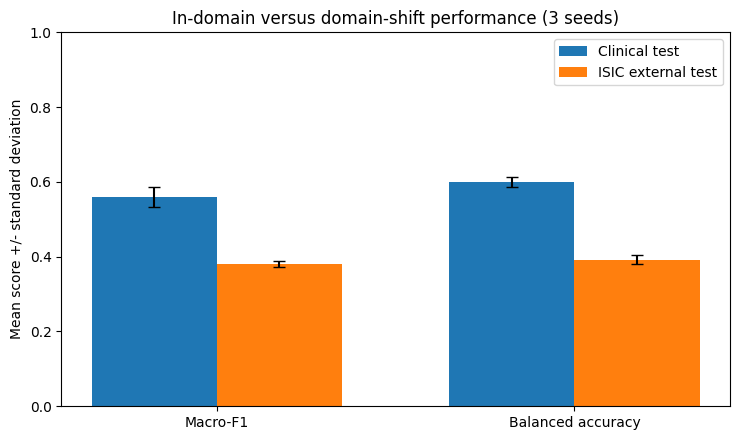

In [4]:
figureRows = aggregateMetrics.loc[aggregateMetrics['metric'].isin(METRIC_NAMES)].copy()
figure, axis = plt.subplots(figsize=(7.5, 4.5))
xPositions = np.arange(len(METRIC_NAMES))
barWidth = 0.35
for datasetIndex, datasetName in enumerate(['clinicalTest', 'isicExternalTest']):
    datasetRows = figureRows.loc[figureRows['dataset'].eq(datasetName)].set_index('metric').reindex(METRIC_NAMES)
    axis.bar(
        xPositions + (datasetIndex - 0.5) * barWidth,
        datasetRows['mean'].to_numpy(),
        barWidth,
        yerr=datasetRows['standardDeviation'].to_numpy(),
        capsize=4,
        label='Clinical test' if datasetName == 'clinicalTest' else 'ISIC external test',
    )
axis.set_xticks(xPositions, ['Macro-F1', 'Balanced accuracy'])
axis.set_ylim(0, 1)
axis.set_ylabel('Mean score +/- standard deviation')
axis.set_title(f'In-domain versus domain-shift performance ({len(randomSeeds)} seeds)')
axis.legend()
figure.tight_layout()
multiSeedFigurePath = runFigureModeRoot / 'multiSeedClinicalVsIsic.png'
figure.savefig(multiSeedFigurePath, dpi=300, bbox_inches='tight')
plt.show()

seedMetricsPath = runModeRoot / 'multiSeedMetrics.csv'
seedMetrics.to_csv(seedMetricsPath, index=False)
multiSeedSummary = {
    'runMode': runMode,
    'paperResultsEligible': runMode == 'full',
    'randomSeeds': list(randomSeeds),
    'seedCount': len(randomSeeds),
    'clinicalTestSampleCountPerSeed': next(iter(clinicalCounts)),
    'isicExternalTestSampleCountPerSeed': next(iter(isicCounts)),
    'aggregation': 'mean and sample standard deviation across independently trained seeds',
    'aggregateMetrics': aggregateRows,
    'aggregateDomainShiftDelta': aggregateDeltas,
    'perSeedResults': {str(seed): summary for seed, summary in seedSummaries.items()},
    'isicUsedForSelection': False,
    'interpretationBoundary': 'Performance differences are empirical domain-shift observations, not clinical efficacy claims.',
}
multiSeedSummaryPath = runModeRoot / 'multiSeedSummary.json'
multiSeedSummaryPath.write_text(json.dumps(multiSeedSummary, indent=2), encoding='utf-8')
assert multiSeedFigurePath.exists() and multiSeedFigurePath.stat().st_size > 0
assert seedMetricsPath.exists() and multiSeedSummaryPath.exists()